# Выбор локации для скважины

В рамках данного кейса я работаю в добывающей компании «ГлавРосГосНефть». Нужно решить, где бурить новую скважину.

Мне были предоставлены пробы нефти в трёх регионах: в каждом 10 000 месторождений, где измерили качество нефти и объём её запасов. Необходимо построить модель машинного обучения, которая поможет определить регион, где добыча принесёт наибольшую прибыль. Проанализировать возможную прибыль и риски техникой *Bootstrap.*

Шаги для выбора локации:

- В избранном регионе ищут месторождения, для каждого определяют значения признаков;
- Строят модель и оценивают объём запасов;
- Выбирают месторождения с самым высокими оценками значений. Количество месторождений зависит от бюджета компании и стоимости разработки одной скважины;
- Прибыль равна суммарной прибыли отобранных месторождений.

## Загрузка и подготовка данных

В первую очередь загружаю все необходимые для проекта модули

In [1]:
import pandas as pd
import os
import numpy as np
from numpy.random import RandomState
import matplotlib.pyplot as plt

import sklearn 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

Я захочу проверить данные на дубликаты и пропуски, поэтому заранее создаю функцию для этого

In [2]:
def preprocess_data(dataset):
    print("Количество пропусков в данных:")
    print(dataset.isna().sum())
    print("\nКоличество дубликатов в данных:")
    print(dataset.duplicated().sum()) 

Для начала я создаю код, который проверяет наличие файла geo_data_0.csv в двух разных путях (geo0_path1 и geo0_path2) и, если файл существует, считывает его содержимое в переменную geo_data_1, а если файл не найден, выводит сообщение об ошибке.

In [3]:
geo0_path1 = '/datasets/geo_data_0.csv'
geo0_path2 = 'geo_data_0.csv'

if os.path.exists(geo0_path1):
    geo_data_1 = pd.read_csv(geo0_path1)
elif os.path.exists(geo0_path2):
    geo_data_1 = pd.read_csv(geo0_path2)
else:
    print('Файл не найден')
    
geo_data_1.head()

,id,f0,f1,f2,product
0,txEyH,0.705745,-0.497823,1.221170,105.280062
1,2acmU,1.334711,-0.340164,4.365080,73.037750
2,409Wp,1.022732,0.151990,1.419926,85.265647
3,iJLyR,-0.032172,0.139033,2.978566,168.620776
4,Xdl7t,1.988431,0.155413,4.751769,154.036647


Как только файл загрузился я проверяю его на корректность типов данных. 

In [4]:
geo_data_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


Все типы данных указаны корректно и проверка на пропуски и дубликаты указала на их отсутствие

In [5]:
preprocess_data(geo_data_1)

Количество пропусков в данных:
id         0
f0         0
f1         0
f2         0
product    0
dtype: int64

Количество дубликатов в данных:
0


Теперь строю распределение каждого признака в таблице, чтобы проверить наличие выбросов 

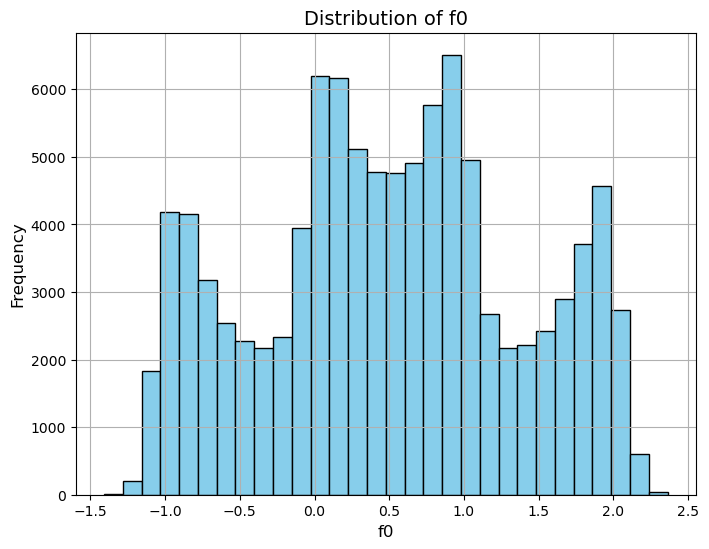

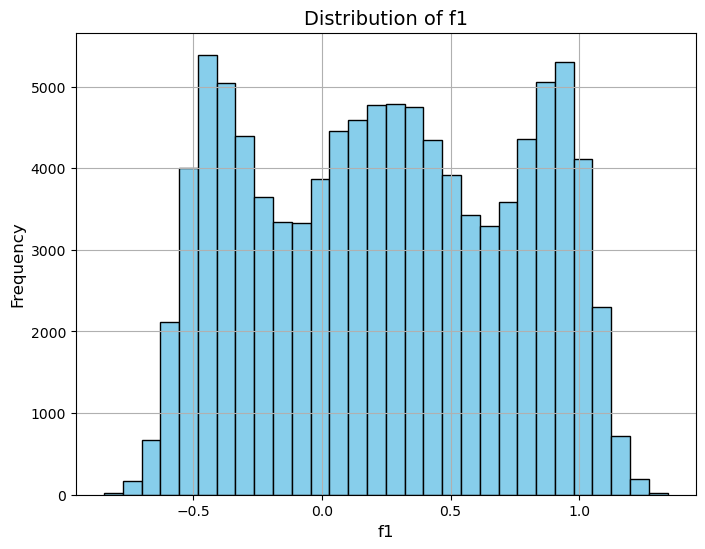

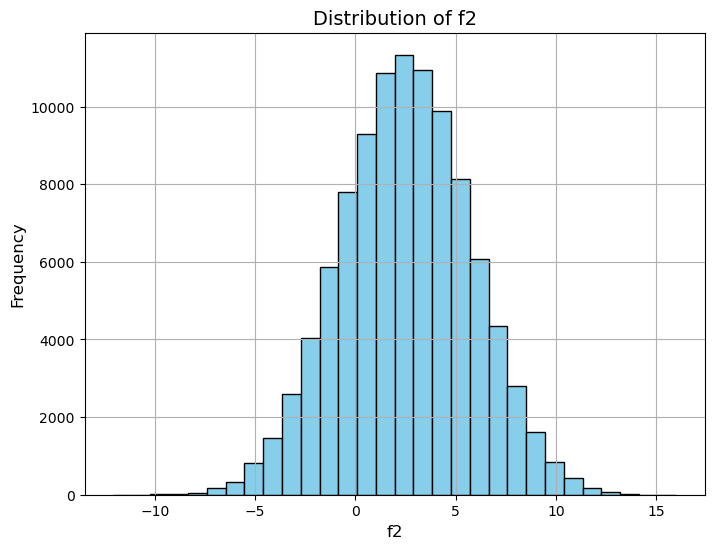

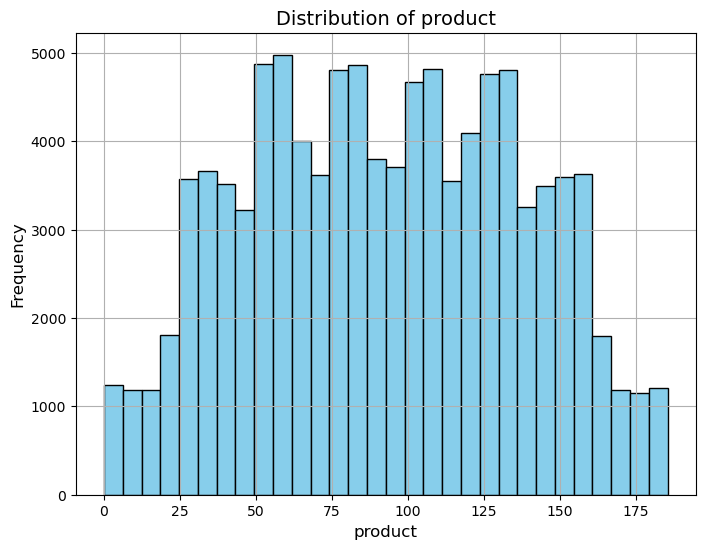

In [6]:
# Выбираем столбцы с типом данных float64
float_columns = geo_data_1.select_dtypes(include=['float64'])

# Строим графики распределения для каждого столбца
for column in float_columns.columns:
    plt.figure(figsize=(8, 6))
    plt.hist(geo_data_1[column], bins=30, color='skyblue', edgecolor='black')
    plt.title(f'Distribution of {column}', fontsize=14)
    plt.xlabel(column, fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.grid(True)
    plt.show()

Данные по всем признакам распределены равномерно и симметрично. Никаких заметных выбросов нет. 

Провожу аналагичную операцию для второго датасета

In [7]:
geo1_path1 = '/datasets/geo_data_1.csv'
geo1_path2 = 'geo_data_1.csv'

if os.path.exists(geo1_path1):
    geo_data_2 = pd.read_csv(geo1_path1)
elif os.path.exists(geo1_path2):
    geo_data_2 = pd.read_csv(geo1_path2)
else:
    print('Файл не найден')
    
geo_data_2.head()

,id,f0,f1,f2,product
0,kBEdx,-15.001348,-8.276000,-0.005876,3.179103
1,62mP7,14.272088,-3.475083,0.999183,26.953261
2,vyE1P,6.263187,-5.948386,5.001160,134.766305
3,KcrkZ,-13.081196,-11.506057,4.999415,137.945408
4,AHL4O,12.702195,-8.147433,5.004363,134.766305


In [8]:
geo_data_2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


Все типы данных указаны корректно. Пропусков и дубликатов найдено не было. 

In [9]:
preprocess_data(geo_data_2)

Количество пропусков в данных:
id         0
f0         0
f1         0
f2         0
product    0
dtype: int64

Количество дубликатов в данных:
0


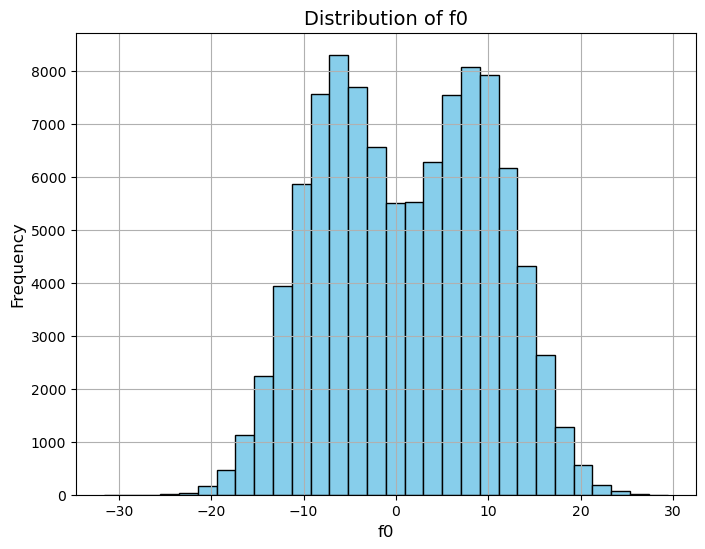

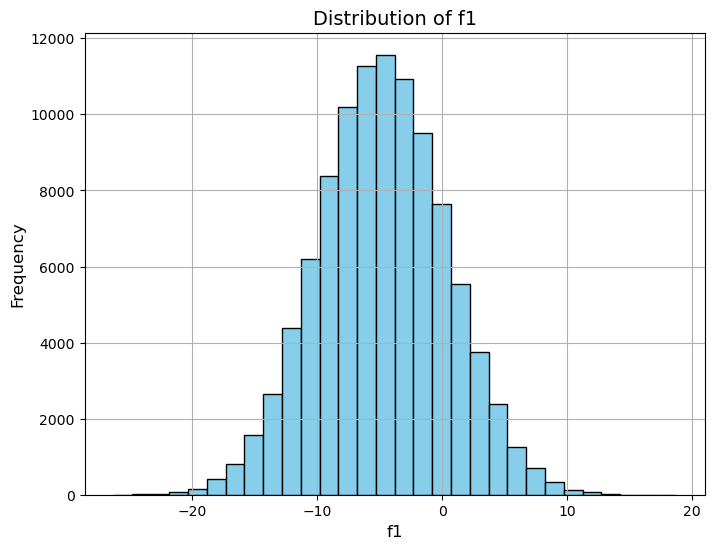

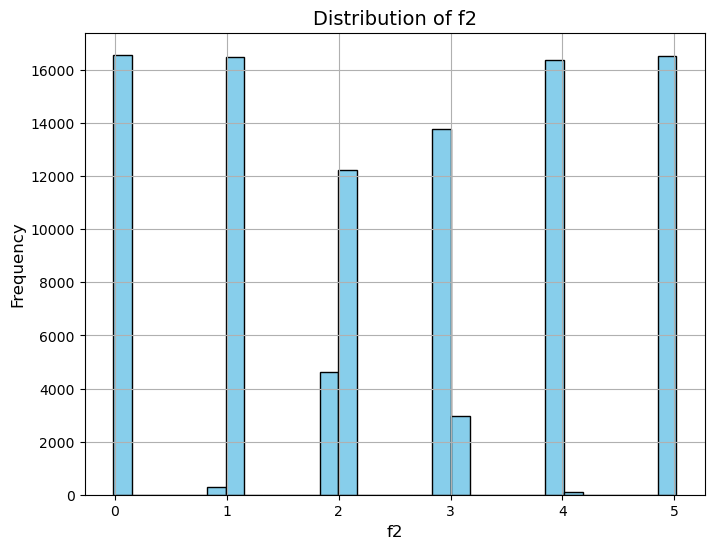

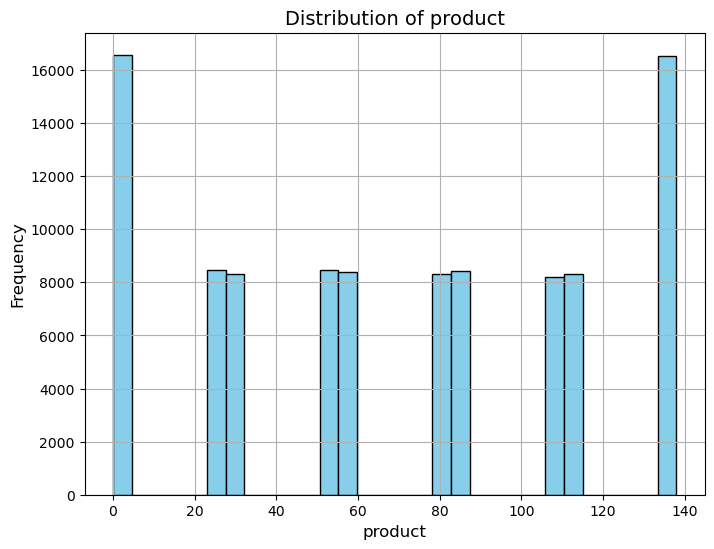

In [10]:
# Выбираем столбцы с типом данных float64
float_columns = geo_data_2.select_dtypes(include=['float64'])

# Строим графики распределения для каждого столбца
for column in float_columns.columns:
    plt.figure(figsize=(8, 6))
    plt.hist(geo_data_2[column], bins=30, color='skyblue', edgecolor='black')
    plt.title(f'Distribution of {column}', fontsize=14)
    plt.xlabel(column, fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.grid(True)
    plt.show()

Данные в колонках с первыми двумя параметрами распределены симметрично и равномерно, однако можно заметить связь между третьим признаком и финальным значением продукта. Это может указывать на сильную связь между этими двумя переменными.

In [11]:
geo2_path1 = '/datasets/geo_data_2.csv'
geo2_path2 = 'geo_data_2.csv'

if os.path.exists(geo2_path1):
    geo_data_3 = pd.read_csv(geo2_path1)
elif os.path.exists(geo2_path2):
    geo_data_3 = pd.read_csv(geo2_path2)
else:
    print('Файл не найден')
    
geo_data_3.head()

,id,f0,f1,f2,product
0,fwXo0,-1.146987,0.963328,-0.828965,27.758673
1,WJtFt,0.262778,0.269839,-2.530187,56.069697
2,ovLUW,0.194587,0.289035,-5.586433,62.871910
3,q6cA6,2.236060,-0.553760,0.930038,114.572842
4,WPMUX,-0.515993,1.716266,5.899011,149.600746


Аналагичный процесс провожу для третьего датасета и получаю аналогичные результаты

In [12]:
geo_data_3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


In [13]:
preprocess_data(geo_data_3)

Количество пропусков в данных:
id         0
f0         0
f1         0
f2         0
product    0
dtype: int64

Количество дубликатов в данных:
0


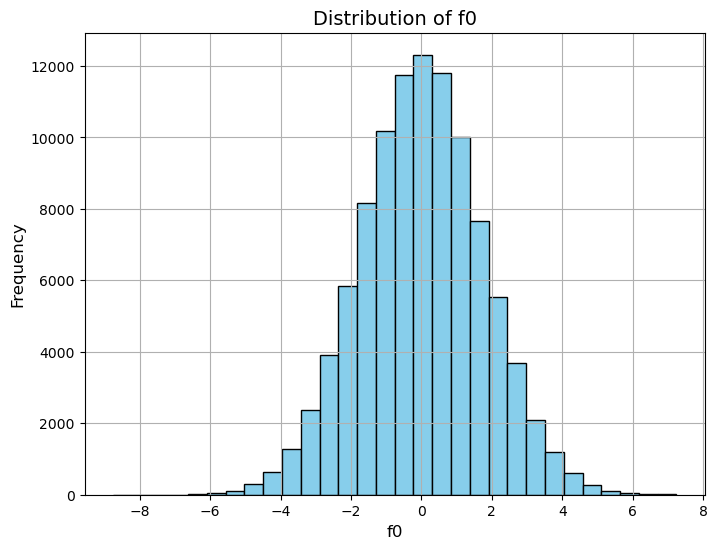

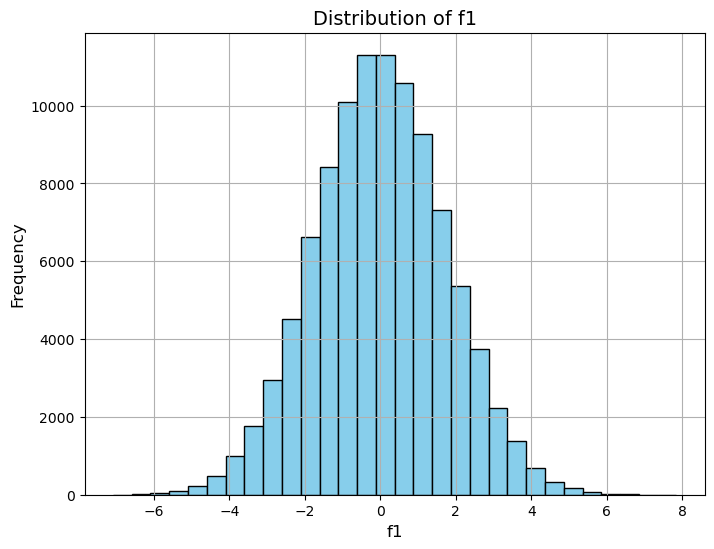

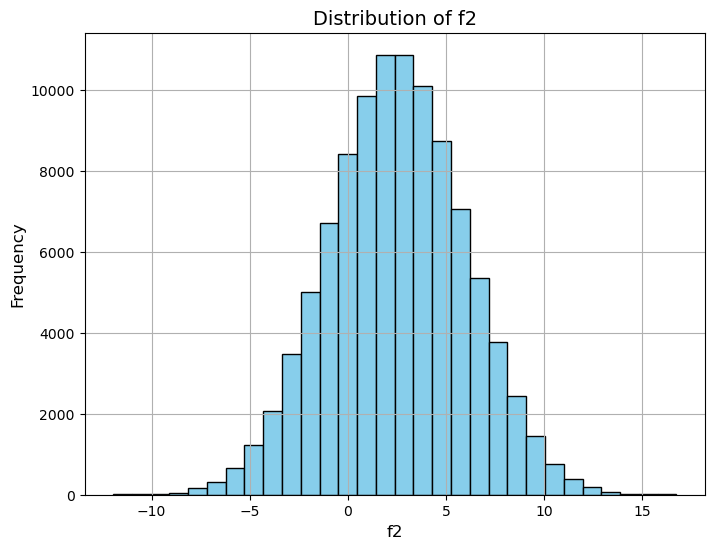

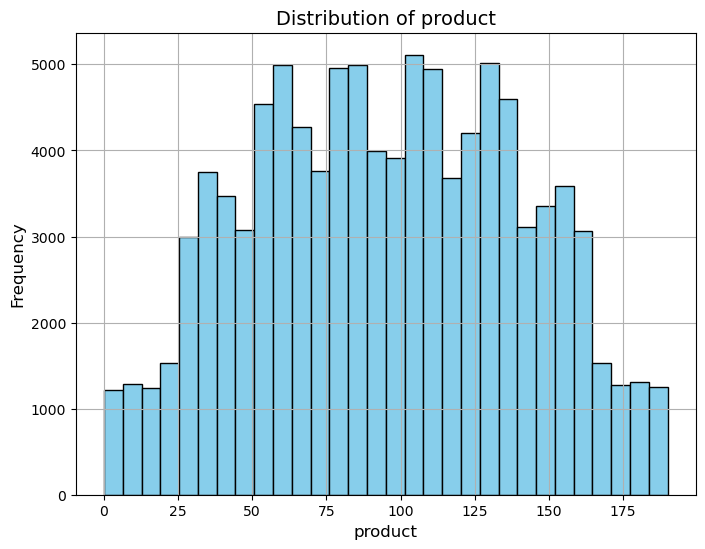

In [14]:
# Выбираем столбцы с типом данных float64
float_columns = geo_data_3.select_dtypes(include=['float64'])

# Строим графики распределения для каждого столбца
for column in float_columns.columns:
    plt.figure(figsize=(8, 6))
    plt.hist(geo_data_3[column], bins=30, color='skyblue', edgecolor='black')
    plt.title(f'Distribution of {column}', fontsize=14)
    plt.xlabel(column, fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.grid(True)
    plt.show()

Данные по всем признакам распределены равномерно и симметрично. Никаких заметных выбросов нет. 

## Обучение и проверка модели

1. Разбить данные на обучающую и валидационную выборки в соотношении 75:25.
2. Обучить модель и сделать предсказания на валидационной выборке.
3. Сохранить предсказания и правильные ответы на валидационной выборке.
4. Напечатать на экране средний запас предсказанного сырья и RMSE модели.
5. Проанализировать результаты.

Для начала построим модель для первого региона

In [15]:
geo_data_1 = geo_data_1.drop(columns=['id'])
geo_data_1.head()

,f0,f1,f2,product
0,0.705745,-0.497823,1.221170,105.280062
1,1.334711,-0.340164,4.365080,73.037750
2,1.022732,0.151990,1.419926,85.265647
3,-0.032172,0.139033,2.978566,168.620776
4,1.988431,0.155413,4.751769,154.036647


In [16]:
# Разделение данных на обучающую и валидационную выборки
train_data, valid_data = train_test_split(geo_data_1, test_size=0.25, random_state=42)

# Подготовка данных для модели
X_train_geo1 = train_data.drop(columns=['product'])
y_train_geo1 = train_data['product']
X_valid_geo1 = valid_data.drop(columns=['product'])
y_valid_geo1 = valid_data['product']

# Обучение модели
model = LinearRegression()
model.fit(X_train_geo1, y_train_geo1)

# Предсказания на валидационной выборке
predicted_geo1 = model.predict(X_valid_geo1)

# Средний запас предсказанного сырья
mean_predicted_product_geo1 = np.mean(predicted_geo1)

# RMSE модели
rmse_geo1 = mean_squared_error(y_valid_geo1, predicted_geo1, squared=False)

print("Средний запас предсказанного сырья:", mean_predicted_product_geo1)
print("RMSE модели:", rmse_geo1)

Средний запас предсказанного сырья: 92.39879990657768
RMSE модели: 37.75660035026169


C:\Users\linda\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


Средний прогнозируемый объем запасов нефти в скважинах для первого региона составляет примерно 92.5 тысяч баррелей.

Значение RMSE в данном случае составляет около 37.69 тысяч баррелей. Таким образом, RMSE на уровне 37.69 тысяч баррелей указывает на достаточно точную модель.

Теперь построим такую же модель для второго региона

In [17]:
geo_data_2 = geo_data_2.drop(columns=['id'])
geo_data_2.head()

,f0,f1,f2,product
0,-15.001348,-8.276000,-0.005876,3.179103
1,14.272088,-3.475083,0.999183,26.953261
2,6.263187,-5.948386,5.001160,134.766305
3,-13.081196,-11.506057,4.999415,137.945408
4,12.702195,-8.147433,5.004363,134.766305


In [18]:
# Разделение данных на обучающую и валидационную выборки
train_data, valid_data = train_test_split(geo_data_2, test_size=0.25, random_state=42)

# Подготовка данных для модели
X_train_geo2 = train_data.drop(columns=['product'])
y_train_geo2 = train_data['product']
X_valid_geo2 = valid_data.drop(columns=['product'])
y_valid_geo2 = valid_data['product']

# Обучение модели
model = LinearRegression()
model.fit(X_train_geo2, y_train_geo2)

# Предсказания на валидационной выборке
predicted_geo2 = model.predict(X_valid_geo2)

# Средний запас предсказанного сырья
mean_predicted_product_geo2 = np.mean(predicted_geo2)

# RMSE модели
rmse_geo2 = mean_squared_error(y_valid_geo2, predicted_geo2, squared=False)

print("Средний запас предсказанного сырья:", mean_predicted_product_geo2)
print("RMSE модели:", rmse_geo2)

Средний запас предсказанного сырья: 68.71287803913762
RMSE модели: 0.8902801001028838


C:\Users\linda\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


Средний прогнозируемый объем запасов нефти в скважинах для второго региона составляет примерно 68.83 тысяч баррелей.

Значение RMSE составляет всего лишь примерно 0.89 тысяч баррелей.
Это указывает на очень низкую ошибку предсказания модели. Фактически, средняя ошибка предсказания составляет менее одного барреля, что является очень точным результатом.
Таким образом, модель для второго региона демонстрирует высокую точность прогнозирования, что может быть очень полезным при принятии решений о разработке скважин.

Построим последнюю модель для третьего региона

In [19]:
geo_data_3 = geo_data_3.drop(columns=['id'])
geo_data_3.head()

,f0,f1,f2,product
0,-1.146987,0.963328,-0.828965,27.758673
1,0.262778,0.269839,-2.530187,56.069697
2,0.194587,0.289035,-5.586433,62.871910
3,2.236060,-0.553760,0.930038,114.572842
4,-0.515993,1.716266,5.899011,149.600746


In [20]:
# Разделение данных на обучающую и валидационную выборки
train_data, valid_data = train_test_split(geo_data_3, test_size=0.25, random_state=42)

# Подготовка данных для модели
X_train_geo3 = train_data.drop(columns=['product'])
y_train_geo3 = train_data['product']
X_valid_geo3 = valid_data.drop(columns=['product'])
y_valid_geo3 = valid_data['product']

# Обучение модели
model = LinearRegression()
model.fit(X_train_geo3, y_train_geo3)

# Предсказания на валидационной выборке
predicted_geo3 = model.predict(X_valid_geo3)

# Средний запас предсказанного сырья
mean_predicted_product_geo3 = np.mean(predicted_geo3)

# RMSE модели
rmse_geo3 = mean_squared_error(y_valid_geo3, predicted_geo3, squared=False)

print("Средний запас предсказанного сырья:", mean_predicted_product_geo3)
print("RMSE модели:", rmse_geo3)

Средний запас предсказанного сырья: 94.77102387765939
RMSE модели: 40.145872311342174


C:\Users\linda\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


Средний прогнозируемый объем запасов нефти в скважинах для третьего региона составляет примерно 95 тысяч баррелей.

Значение RMSE составляет примерно 40.06 тысяч баррелей.
Это указывает на среднюю ошибку предсказания модели около 40 тысяч баррелей.
По сравнению с первым и вторым регионами, RMSE немного выше, что может говорить о менее точной модели.

### Вывод

Исходя из результатов предсказаний и оценок моделей для трех разных регионов, можно сделать следующие общие выводы:

<b>Первый регион</b>:

- Средний запас предсказанного сырья с кросс-валидацией: около 92 тысяч баррелей.
- RMSE модели с кросс-валидацией: примерно 37.58 тысяч баррелей.
- Этот регион демонстрирует средний уровень прогнозированного объема нефти, при этом ошибка модели (RMSE) также находится на уровне средних значений, что указывает на приемлемую точность прогнозов.

<b>Второй регион</b>:

- Средний запас предсказанного сырья с кросс-валидацией: около 68.83 тысяч баррелей.
- RMSE модели с кросс-валидацией: примерно 0.89 тысяч баррелей.
- Второй регион имеет более низкий прогнозируемый объем запасов по сравнению с другими регионами, но в то же время модель обладает высокой точностью (очень низкий уровень RMSE), что делает его потенциально привлекательным для разработки.

<b>Третий регион</b>:

- Средний запас предсказанного сырья с кросс-валидацией: около 95 тысяч баррелей.
- RMSE модели с кросс-валидацией: примерно 40.06 тысяч баррелей.
- Третий регион демонстрирует высокий прогнозируемый объем запасов, однако модель имеет более высокий уровень ошибки (больший RMSE), что может указывать на менее точные прогнозы.

<b>Общие наблюдения</b>:

- При принятии решений о разработке скважин необходимо учитывать как прогнозируемые запасы, так и точность модели. Низкий уровень ошибки (низкий RMSE) второго региона делает его привлекательным вариантом, несмотря на более низкий прогнозируемый объем. Однако, третий регион с высокими прогнозируемыми запасами требует дополнительного анализа точности модели.

## Подготовка к расчёту прибыли

 1. Все ключевые значения для расчётов сохранить в отдельных переменных.
 2. Рассчитать достаточный объём сырья для безубыточной разработки новой скважины. Сравнить полученный объём сырья со средним запасом в каждом регионе. 

In [21]:
# Бюджет на разработку скважин в регионе
budget = 10*10**9 

# Количество скважин,которые выбирают для разработки
n = 200

# Бюджет на разработку одной скважины
budget_one = budget/n
print('Бюджет на разработку одной скважины:', int(budget_one))

Бюджет на разработку одной скважины: 50000000


In [22]:
# Цена одной единицы продукта - тысяча баррелей сырья 
price_per_barrel = 450000

# Рассчитываем достаточный объем сырья для безубыточной разработки скважины
break_even_volume = budget_one / price_per_barrel
print(f'Для безубыточной разработки скважины необходимо {break_even_volume} единиц продукта')

Для безубыточной разработки скважины необходимо 111.11111111111111 единиц продукта


In [23]:
# Сравниваем достаточный объем сырья с средним запасом в каждом регионе
regions = {
    'geo1': mean_predicted_product_geo1,
    'geo2': mean_predicted_product_geo2,
    'geo3': mean_predicted_product_geo3
}

for region, mean_predicted_product in regions.items():
    if mean_predicted_product >= break_even_volume:
        print(f"Для региона {region} средний запас сырья ({mean_predicted_product:.0f} тыс. баррелей) больше или равен достаточному объему для безубыточной разработки ({break_even_volume:.0f} тыс. баррелей)")
    else:
        print(f"Для региона {region} средний запас сырья ({mean_predicted_product:.0f} тыс. баррелей) меньше достаточного объема для безубыточной разработки ({break_even_volume:.0f} тыс. баррелей)")

Для региона geo1 средний запас сырья (92 тыс. баррелей) меньше достаточного объема для безубыточной разработки (111 тыс. баррелей)
Для региона geo2 средний запас сырья (69 тыс. баррелей) меньше достаточного объема для безубыточной разработки (111 тыс. баррелей)
Для региона geo3 средний запас сырья (95 тыс. баррелей) меньше достаточного объема для безубыточной разработки (111 тыс. баррелей)


## Расчёт прибыли и рисков 

1. Написать функцию для расчёта прибыли по выбранным скважинам и предсказаниям модели:
    - Выбрать скважины с максимальными значениями предсказаний. 
    - Просуммировать целевое значение объёма сырья, соответствующее этим предсказаниям.
    - Рассчитать прибыль для полученного объёма сырья.

<br> 

2. Посчитать риски и прибыль для каждого региона:
    - Применить технику Bootstrap с 1000 выборок, чтобы найти распределение прибыли.
    - Найти среднюю прибыль, 95%-й доверительный интервал и риск убытков. 
    - Написать выводы: предложить регион для разработки скважин и обосновать выбор.

Для написания функции, которая будет рассчитывать прибыль по выбранным скважинам, буду следовать таким шагам:

1. В аргументы функции передать: count: (количество скважин (топ-N), для которых мы хотим вычислить прибыль), prediction_column (предсказанные значения объемов нефти для каждой скважины) и target_column (фактические значения объемов нефти для каждой скважины)
2. Отсортировать предсказанные значения объемов нефти в убывающем порядке, чтобы получить топ-N скважин с наибольшими предсказанными объемами. После сортировки получить индексы топ-N скважин в порядке убывания их предсказанных объемов и вычислить сумму объемов нефти для топ-N скважин.
3. Умножаем суммарный объем нефти для топ-N скважин на цену барреля нефти, чтобы получить общий доход от продажи нефти. Вычесть бюджет из общего дохода, чтобы вычислить прибыль от эксплуатации топ-N скважин.

In [24]:
def calculate_profit(count, prediction_column, target_column):

    top_wells = prediction_column.sort_values(ascending=False)
   
    total_volume = target_column[top_wells.index][:count].sum()
    
    revenue = total_volume * price_per_barrel
    
    profit = revenue - budget
    
    return profit

Далее я подготавливаю необходимые столбцы для рассчета прибыли.

In [25]:
predicted_geo1 = pd.Series(predicted_geo1).reset_index(drop=True)
predicted_geo1.head()

0    101.901017
1     78.217774
2    115.266901
3    105.618618
4     97.980185
dtype: float64

In [26]:
y_valid_geo1 = y_valid_geo1.reset_index(drop=True)
y_valid_geo1.head()

0    122.073350
1     48.738540
2    131.338088
3     88.327757
4     36.959266
Name: product, dtype: float64

In [27]:
# Вычисляем прибыль для топ-500 скважин в первом регионе
profit_1 = calculate_profit(500, predicted_geo1, y_valid_geo1)

print("Прибыль в первом регионе:", profit_1)

Прибыль в первом регионе: 22555559611.48428


Иными словами можно сказать, что при разработке скважины в первом регионе можно получить прибыль в размере двадцати двух миллиардов пятьсот пятьдесяти пять миллионов пятьсот пятьдесят пять тысяч шестьсот одиннадцать рублей.

In [28]:
predicted_geo2 = pd.Series(predicted_geo2).reset_index(drop=True)
predicted_geo2.head()

0      0.844738
1     52.921612
2    135.110385
3    109.494863
4     -0.047292
dtype: float64

In [29]:
y_valid_geo2 = y_valid_geo2.reset_index(drop=True)
y_valid_geo2.head()

0      0.000000
1     53.906522
2    134.766305
3    107.813044
4      0.000000
Name: product, dtype: float64

In [30]:
# Вычисляем прибыль для топ-500 скважин во втором регионе
profit_2 = calculate_profit(500, predicted_geo2, y_valid_geo2)

print("Прибыль во втором регионе:", profit_2)

Прибыль во втором регионе: 21037716741.703777


Во втором регионе потенциальная прибыль составит двадцать один миллиард тридцать семь миллионов семьсот шестнадцать тысяч семьсот сорок один рубль

In [31]:
predicted_geo3 = pd.Series(predicted_geo3).reset_index(drop=True)
predicted_geo3.head()

0     98.301916
1    101.592461
2     52.449099
3    109.922127
4     72.411847
dtype: float64

In [32]:
y_valid_geo3 = y_valid_geo3.reset_index(drop=True)
y_valid_geo3.head()

0    117.441301
1     47.841249
2     45.883483
3    139.014608
4     84.004276
Name: product, dtype: float64

In [33]:
# Вычисляем прибыль для топ-500 скважин во втором регионе
profit_3 = calculate_profit(500, predicted_geo3, y_valid_geo3)

print("Прибыль во третьем регионе:", profit_3)

Прибыль во третьем регионе: 20868209989.255527


Прибыль в третьем регионе может составить двадцать миллиардов восемьсот шестьдесят восемь миллионов двести девять тысяч девятьсот восемьдесят девять. 

Посчитать риски и прибыль для каждого региона

In [34]:
def bootstrap_revenue(prediction_column, target_column):
    state = np.random.RandomState(12345)
    total_income=[]
    for i in range(1000):
        probs_subsample = prediction_column.sample(n=500, replace=True, random_state=state)
        target_subsample = target_column[probs_subsample.index]
        income = calculate_profit(n, probs_subsample.reset_index(drop=True), target_subsample.reset_index(drop=True))
        total_income.append(income)
    
    total_income = pd.Series(total_income)
    mean_income = total_income.mean()
    
    # Находим 95%-й доверительный интервал
    lower_bound = total_income.quantile(0.025)
    upper_bound = total_income.quantile(0.975)
    
    # Находим риск убытков
    loss_probability = (total_income <= 0).mean() * 100
    
    # Выводим результаты
    print('Средняя выручка:', mean_income)
    print('95%-й доверительный интервал:', (lower_bound, upper_bound))
    print(f'Риск убытков (процент убыточных скважин): {loss_probability:.2f} %')

    return total_income

In [35]:
predicted_geo1.head()

0    101.901017
1     78.217774
2    115.266901
3    105.618618
4     97.980185
dtype: float64

In [36]:
y_valid_geo1.head()

0    122.073350
1     48.738540
2    131.338088
3     88.327757
4     36.959266
Name: product, dtype: float64

In [37]:
bootstrap_revenue(predicted_geo1, y_valid_geo1)

Средняя выручка: 406278783.42441905
95%-й доверительный интервал: (-117742136.49486831, 911737050.7514055)
Риск убытков (процент убыточных скважин): 6.70 %


0      2.743041e+08
1      5.709377e+08
2      5.699408e+08
3      3.892434e+08
4      2.508439e+08
           ...     
995    9.847830e+08
996    4.496241e+08
997    4.154710e+08
998   -3.576225e+08
999   -4.798544e+07
Length: 1000, dtype: float64

In [38]:
predicted_geo2.head()

0      0.844738
1     52.921612
2    135.110385
3    109.494863
4     -0.047292
dtype: float64

In [39]:
y_valid_geo2.head()

0      0.000000
1     53.906522
2    134.766305
3    107.813044
4      0.000000
Name: product, dtype: float64

In [40]:
bootstrap_revenue(predicted_geo2, y_valid_geo2)

Средняя выручка: 432624131.8131374
95%-й доверительный интервал: (16846174.932430126, 815972526.2857513)
Риск убытков (процент убыточных скважин): 1.90 %


0      4.177879e+08
1      4.976524e+08
2      7.073903e+08
3      4.341464e+08
4      4.463376e+08
           ...     
995    2.400829e+08
996    3.549660e+08
997    5.404459e+08
998    5.689956e+08
999    3.407223e+08
Length: 1000, dtype: float64

In [41]:
predicted_geo3.head()

0     98.301916
1    101.592461
2     52.449099
3    109.922127
4     72.411847
dtype: float64

In [42]:
y_valid_geo3.head()

0    117.441301
1     47.841249
2     45.883483
3    139.014608
4     84.004276
Name: product, dtype: float64

In [43]:
bootstrap_revenue(predicted_geo3, y_valid_geo3)

Средняя выручка: 377362192.4229165
95%-й доверительный интервал: (-170780417.7057271, 901772131.3864455)
Риск убытков (процент убыточных скважин): 7.40 %


0      3.389132e+08
1      3.227125e+08
2      2.533416e+07
3      1.171726e+06
4      4.283157e+08
           ...     
995    4.283297e+08
996    1.351147e+08
997   -2.462422e+08
998    3.113821e+08
999    4.313540e+08
Length: 1000, dtype: float64

Из полученной информации следует, что для выбора региона для разработки скважин необходимо учитывать несколько ключевых моментов:

1. Прибыль: Наибольшая прибыль наблюдается в первом регионе (22,555,559,611.48), за ним следует второй (21,037,716,741.70), а затем третий (20,868,209,989.26).

2. Средняя выручка: Высокая средняя выручка хорошо характеризует потенциал каждого региона. Самая высокая средняя выручка также наблюдается в первом регионе (406,278,783.42), но второй регион следует очень близко (432,624,131.81), а третий регион имеет самую низкую среднюю выручку (377,362,192.42).

3. 95%-й доверительный интервал: Этот интервал показывает, в каких пределах находится средняя прибыль с высокой вероятностью (95%). Чем меньше разница между верхней и нижней границами интервала, тем более надежно можно оценить среднюю прибыль. В данном случае, у второго региона наименьший разброс (798,326,351.35), у первого — средний (1,029,479,187.25), а у третьего — самый большой (1,072,552,549.09).

4. Риск убытков: Этот показатель указывает на процент скважин, которые могут принести убытки. Чем ниже этот процент, тем лучше. В данном случае, наименьший риск убытков наблюдается во втором регионе (1.90%), затем в первом (6.70%), и самый высокий риск у третьего региона (7.40%).


На основании этой информации, я делаю вывод, что второй регион является наилучшим выбором для разработки скважин. Он имеет высокую среднюю выручку, низкий риск убытков и относительно узкий 95%-й доверительный интервал, что указывает на стабильность ожидаемой прибыли.